# Attention

Open in [Google Colab](https://colab.research.google.com/github/febse/ta/blob/main/class/06-01-Attention.ipynb)

A word has the same embedding vector wherever it appears: "rabbit" in "the white rabbit" and "rabbit" in "alice saw the rabbit" start from the same row of the embedding matrix. In the [recurrent networks](03-12-RNN-Next-Word-Prediction.ipynb) the context entered through the hidden state, which was passed from word to word and had to squeeze everything that was read so far into one vector. **Attention** [@VASWANI2017AttentionAllYou] takes another route: to build the new representation of a word, the network looks at **all** words of the sentence directly and takes a **weighted average** of their (transformed) vectors. The weights say how much attention the word pays to each of the others, and they are computed from the vectors themselves.

This chapter covers only the basic building block: **single-head scaled dot-product self-attention** on one sentence. We first compute everything by hand (in numpy) on a five-word sentence, and then train a tiny network with an attention layer on a toy task with a six-word vocabulary. Not covered: several heads, masking, positional information (see the [next chapter](07-01-Positional-Encodings.ipynb)) and the rest of the Transformer.

The notation follows the earlier chapters: the vectors are **row** vectors, so a linear map is $x W$.

## Queries, Keys and Values

Let a sentence have $T$ tokens, and let $X$ be the $T \times d_{\text{model}}$ matrix whose row $x_t$ is the embedding of the token at position $t$. Attention uses three weight matrices, which are learned like all other weights:

:::{.ex-class}
$$
Q = X W_Q, \qquad K = X W_K, \qquad V = X W_V, \qquad W_Q, W_K, W_V \in \mathbb{R}^{d_{\text{model}} \times d_k}.
$$
:::

Every token thus gets three vectors of size $d_k$ (we use the same size for all three):

- the **query** $q_t$: what the token at position $t$ is *looking for*;
- the **key** $k_s$: what the token at position $s$ *offers* to be found by;
- the **value** $v_s$: the *content* that the token at position $s$ passes on if it is attended to.

The names come from the analogy with a dictionary lookup, except that the lookup is soft: instead of returning the value of the one key that matches the query, we return a mixture of all values, with more weight on the values whose keys match the query better.

**Step 1: scores.** The match between the query of token $t$ and the key of token $s$ is the dot product, divided by $\sqrt{d_k}$ (see below):

:::{.ex-class}
$$
S_{ts} = \frac{q_t \cdot k_s}{\sqrt{d_k}}, \qquad S = \frac{Q K^\top}{\sqrt{d_k}} \in \mathbb{R}^{T \times T}.
$$
:::

**Step 2: attention weights.** Row $t$ of $S$ holds the scores of token $t$ for all $T$ tokens. We turn each row into a probability distribution with the softmax (the same function as in the [multi-class chapter](03-07-ANN-Multiclass-Classification.ipynb)):

:::{.ex-class}
$$
A_{ts} = \frac{\exp(S_{ts})}{\sum_{r=1}^{T} \exp(S_{tr})}, \qquad A_{ts} \ge 0, \quad \sum_{s=1}^{T} A_{ts} = 1.
$$
:::

**Step 3: output.** The new representation of token $t$ is the weighted average of the value vectors:

:::{.ex-class}
$$
o_t = \sum_{s=1}^{T} A_{ts}\, v_s, \qquad O = A V \in \mathbb{R}^{T \times d_k}.
$$
:::

All three steps together: $O = \text{softmax}\left( Q K^\top / \sqrt{d_k} \right) V$, with the softmax applied to every row. Note that every token attends to **all** tokens of the sentence, including itself, and that the number of tokens $T$ does not appear in any weight matrix: the same $W_Q, W_K, W_V$ work for sentences of any length.

## A Small Example

We use the sentence "alice saw the white rabbit". The vocabulary has five words, the embeddings have $d_{\text{model}} = 4$ coordinates, and queries, keys and values have $d_k = 2$ coordinates, so that every number can be printed. The embeddings and the weight matrices are random numbers (rounded to one decimal), so the attention pattern that comes out is arbitrary; it has no linguistic meaning until the weights are trained (next section).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

vocabulary = ["alice", "saw", "the", "white", "rabbit"]
word_to_id = {word: i for i, word in enumerate(vocabulary)}

d_model = 4                                      # size of the word vectors
rng = np.random.default_rng(3)
embeddings = np.round(rng.normal(size=(len(vocabulary), d_model)), 1)     # one row per word (random, rounded to be readable)

sentence = ["alice", "saw", "the", "white", "rabbit"]
X = embeddings[[word_to_id[w] for w in sentence]]                          # T x d_model, one row per token
pd.DataFrame(X, index=sentence, columns=[f"x{j + 1}" for j in range(d_model)])

,x1,x2,x3,x4
alice,2.0,-2.6,0.4,-0.6
saw,-0.5,-0.2,-2.0,-0.2
the,-0.9,3.3,0.2,-0.4
white,-0.3,-0.7,-1.1,-0.4
rabbit,0.5,-0.2,1.0,-0.2


In [2]:
d_k = 2                                          # size of the queries, keys and values
W_Q = np.round(rng.normal(size=(d_model, d_k)), 1)
W_K = np.round(rng.normal(size=(d_model, d_k)), 1)
W_V = np.round(rng.normal(size=(d_model, d_k)), 1)

Q, K, V = X @ W_Q, X @ W_K, X @ W_V              # each T x d_k
print("shapes:", X.shape, W_Q.shape, "->", Q.shape)
pd.concat({"queries Q": pd.DataFrame(Q, index=sentence).round(2),
           "keys K": pd.DataFrame(K, index=sentence).round(2),
           "values V": pd.DataFrame(V, index=sentence).round(2)}, axis=1)

shapes: (5, 4) (4, 2) -> (5, 2)


queries Q       keys K       values V      
               0     1      0     1        0     1
alice      -2.52  4.68   2.24  2.60    -2.64  7.36
saw        -0.08 -1.59  -1.54 -1.78     1.08 -1.34
the         0.85 -2.78  -2.65 -2.05    -0.56 -5.93
white      -0.89 -0.53  -0.34 -1.03     1.37  0.56
rabbit     -0.68  1.41   0.96  1.02    -0.82  1.76

Each row of $Q$, $K$ and $V$ belongs to one token. Next the scores: the entry in row $t$ and column $s$ is the scaled dot product of the query of token $t$ with the key of token $s$.

In [3]:
scores = Q @ K.T / np.sqrt(d_k)                  # T x T: scores[t, s] = q_t . k_s / sqrt(d_k)
pd.DataFrame(scores, index=sentence, columns=sentence).round(2)

,alice,saw,the,white,rabbit
alice,4.61,-3.15,-2.06,-2.80,1.66
saw,-3.05,2.09,2.45,1.18,-1.20
the,-3.76,2.57,2.44,1.82,-1.43
white,-2.38,1.64,2.44,0.60,-0.99
rabbit,1.52,-1.03,-0.77,-0.86,0.56


The softmax turns every row of scores into weights that are positive and sum to one. Large scores get most of the weight.

In [4]:
def softmax_rows(scores):
    shifted = scores - scores.max(axis=1, keepdims=True)       # subtracting the row maximum does not change the result but avoids overflow
    exp_scores = np.exp(shifted)
    return exp_scores / exp_scores.sum(axis=1, keepdims=True)

A = softmax_rows(scores)                         # attention weights, T x T
attention_table = pd.DataFrame(A, index=sentence, columns=sentence)
print("row sums:", A.sum(axis=1))
attention_table.round(2)

row sums: [1. 1. 1. 1. 1.]


,alice,saw,the,white,rabbit
alice,0.95,0.00,0.00,0.00,0.05
saw,0.00,0.35,0.50,0.14,0.01
the,0.00,0.42,0.37,0.20,0.01
white,0.00,0.27,0.61,0.10,0.02
rabbit,0.60,0.05,0.06,0.06,0.23


Row $t$ of this table says how the token $t$ distributes its attention. Finally, the output of token $t$ is the weighted sum of the value vectors with these weights. For "rabbit" we also compute the sum explicitly to show that the matrix product $A V$ does exactly that.

In [5]:
O = A @ V                                        # T x d_k: every output is a weighted average of the value vectors
t = sentence.index("rabbit")
manual = sum(A[t, s] * V[s] for s in range(len(sentence)))
print("output for 'rabbit' (A @ V):", O[t].round(3))
print("weighted sum of the values :", manual.round(3))
pd.DataFrame(O, index=sentence).round(2)

output for 'rabbit' (A @ V): [-1.691  4.456]
weighted sum of the values : [-1.691  4.456]


,0,1
alice,-2.54,7.06
saw,0.27,-3.31
the,0.51,-2.63
white,0.06,-3.83
rabbit,-1.69,4.46


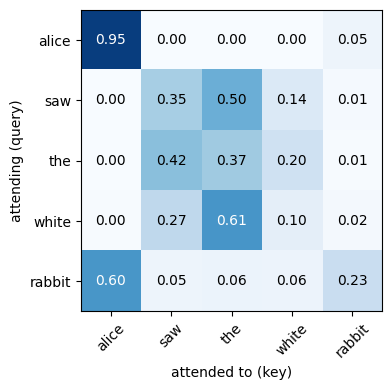

In [6]:
# no-ex-class
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(A, cmap="Blues", vmin=0, vmax=1)
ax.set(xticks=range(len(sentence)), yticks=range(len(sentence)), xlabel="attended to (key)", ylabel="attending (query)")
ax.set_xticklabels(sentence, rotation=45)
ax.set_yticklabels(sentence)
for t in range(len(sentence)):
    for s in range(len(sentence)):
        ax.text(s, t, f"{A[t, s]:.2f}", ha="center", va="center", color="white" if A[t, s] > 0.5 else "black")
plt.tight_layout()
plt.show()

The pattern is arbitrary because the weights are random, but we can read the mechanics from it. "alice" puts 95% of its attention on itself, "saw", "the" and "white" mostly attend to "saw" and "the" (and nobody attends to "alice" in those rows: the weights are 0.00), and "rabbit" attends mostly to "alice" (0.60) and only 23% to itself. Every row sums to 1, and the output of a token is a mixture of the values of the tokens it attends to: the output of "alice" is almost exactly its own value vector, whereas the output of "rabbit" is a mixture dominated by the value of "alice".

We collect the three steps in a function. It is all that single-head self-attention does.

In [7]:
def self_attention(X, W_Q, W_K, W_V):
    Q, K, V = X @ W_Q, X @ W_K, X @ W_V
    A = softmax_rows(Q @ K.T / np.sqrt(K.shape[1]))
    return A @ V, A

output, weights = self_attention(X, W_Q, W_K, W_V)
print("same result as above:", np.allclose(output, O) and np.allclose(weights, A))

same result as above: True


### Why Divide by $\sqrt{d_k}$?

A dot product of two vectors with $d_k$ coordinates is a sum of $d_k$ products. If the coordinates are independent with mean 0 and variance 1, the dot product has variance $d_k$, so its standard deviation is $\sqrt{d_k}$. For large $d_k$ the scores therefore become large in absolute value, the softmax saturates (one weight close to 1, the others close to 0), and its gradient becomes very small. Dividing by $\sqrt{d_k}$ brings the scores back to variance 1 for any $d_k$. The table shows this for random vectors: the average largest weight of the softmax of 10 scores.

In [8]:
# no-ex-class
# Why divide by sqrt(d_k)? The dot product of two random vectors grows with d_k.
rng_check = np.random.default_rng(0)
print(f"{'d_k':>5} {'std of q.k':>11} {'std of q.k/sqrt(d_k)':>22} {'largest weight, unscaled':>26} {'largest weight, scaled':>24}")
for d in [2, 16, 128, 1024]:
    q = rng_check.normal(size=(1000, d))                     # 1000 queries
    k = rng_check.normal(size=(10, d))                       # 10 keys
    raw = q @ k.T
    print(f"{d:>5} {raw.std():>11.2f} {(raw / np.sqrt(d)).std():>22.2f} "
          f"{softmax_rows(raw).max(axis=1).mean():>26.2f} {softmax_rows(raw / np.sqrt(d)).max(axis=1).mean():>24.2f}")

  d_k  std of q.k   std of q.k/sqrt(d_k)   largest weight, unscaled   largest weight, scaled
    2        1.43                   1.01                       0.41                     0.32
   16        4.01                   1.00                       0.74                     0.32
  128       11.80                   1.04                       0.91                     0.33
 1024       32.20                   1.01                       0.97                     0.32


The standard deviation of the unscaled dot product grows like $\sqrt{d_k}$ (1.4, 4.0, 11.8, 32.2), and the softmax over 10 scores puts on average 41% of the weight on the largest score for $d_k = 2$ but 97% for $d_k = 1024$, almost a hard choice. After dividing by $\sqrt{d_k}$ the standard deviation is 1 and the largest weight stays at about 0.32 for all $d_k$.

### Attention Does Not Know the Word Order

If we shuffle the tokens of the sentence, the queries, keys and values of every token stay the same (they depend only on the embedding of the token), and so do the scores between any two tokens. The output is therefore the same, only shuffled in the same way: self-attention is **permutation equivariant**.

In [9]:
# no-ex-class
# Shuffling the tokens only shuffles the rows of the output
order = np.array([4, 2, 0, 3, 1])
output_shuffled, _ = self_attention(X[order], W_Q, W_K, W_V)
print("shuffled sentence:", [sentence[i] for i in order])
print("output rows are the original rows in the new order:", np.allclose(output_shuffled, output[order]))

shuffled sentence: ['rabbit', 'the', 'alice', 'white', 'saw']
output rows are the original rows in the new order: True


So "alice saw the rabbit" and "rabbit saw the alice" would get the same set of output vectors. To let the model know where a word is, the position has to be added to the embedding; this is the topic of the [positional encodings chapter](07-01-Positional-Encodings.ipynb).

## A Tiny Trained Example

In the example above the weights were random. Now we let a network learn them. The toy task is designed so that **one attention layer is enough**, and so that we can see what it learned.

**The task.** The vocabulary has six words: five characters, `queen`, `rabbit`, `alice`, `cat`, `tea`, and the symbol `?`. A sentence consists of three characters (repetitions are allowed) followed by `?`, e.g. "tea alice cat ?". The target is the **most important** of the three characters, where the importance is given by the order of the list above (the `queen` beats the `rabbit`, which beats `alice`, and so on). The network is **not told** this order; it has to learn it from examples. There are $5^3 = 125$ sentences, we train on 90 of them and keep 35 for testing.

In [10]:
import itertools
import torch
import torch.nn as nn

# tiny vocabulary; "?" marks the position whose answer we want
characters = ["queen", "rabbit", "alice", "cat", "tea"]        # hidden rule: the earlier in this list, the more important
vocab_small = ["?"] + characters
small_id = {w: i for i, w in enumerate(vocab_small)}

# every sentence: 3 characters (repetitions allowed), followed by "?"; the target is the most important of the 3
sentences = [list(p) + ["?"] for p in itertools.product(characters, repeat=3)]
targets = [min(s[:3], key=characters.index) for s in sentences]
X_ids = torch.tensor([[small_id[w] for w in s] for s in sentences])
y_ids = torch.tensor([characters.index(t) for t in targets])

torch.manual_seed(0)
perm = torch.randperm(len(sentences))
train_idx, test_idx = perm[:90], perm[90:]
print(len(sentences), "possible sentences,", len(train_idx), "for training,", len(test_idx), "for testing")
for k in range(3):
    print(sentences[k], "->", targets[k])

125 possible sentences, 90 for training, 35 for testing
['queen', 'queen', 'queen', '?'] -> queen
['queen', 'queen', 'rabbit', '?'] -> queen
['queen', 'queen', 'alice', '?'] -> queen


**The network.** An embedding layer ($d_{\text{model}} = 8$), the single-head attention layer from above ($d_k = 8$, now with trainable $W_Q, W_K, W_V$), and a linear output layer with five classes (one per character) that reads the output of the position of the `?`. In the notation above, the network uses the row $o_T$ of the output of the attention layer, where $T$ is the position of `?`:

$$
\hat{y} = \text{softmax}\left( o_T W_{\text{out}} + b_{\text{out}} \right), \qquad o_T = \sum_{s=1}^{T} A_{Ts}\, v_s .
$$

To answer correctly the query of `?` has to give a high score to the key of the most important character, so that its value (which can encode the identity of the character) dominates the weighted sum.

In [11]:
class SingleHeadAttention(nn.Module):
    def __init__(self, d_model, d_k):
        super().__init__()
        self.W_Q = nn.Linear(d_model, d_k, bias=False)
        self.W_K = nn.Linear(d_model, d_k, bias=False)
        self.W_V = nn.Linear(d_model, d_k, bias=False)
        self.d_k = d_k

    def forward(self, X):                                        # X: (batch, T, d_model)
        Q, K, V = self.W_Q(X), self.W_K(X), self.W_V(X)
        A = torch.softmax(Q @ K.transpose(1, 2) / self.d_k ** 0.5, dim=-1)       # (batch, T, T)
        return A @ V, A


class AttentionClassifier(nn.Module):
    def __init__(self, vocab_size, n_classes, d_model=8, d_k=8):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, d_model)
        self.attention = SingleHeadAttention(d_model, d_k)
        self.output = nn.Linear(d_k, n_classes)

    def forward(self, word_ids):
        out, A = self.attention(self.embedding(word_ids))
        return self.output(out[:, -1]), A                        # the answer is read from the position of "?"

We train with the cross-entropy loss and the Adam optimizer on the 90 training sentences (full batch, a fixed random seed).

In [12]:
torch.manual_seed(0)
model = AttentionClassifier(len(vocab_small), len(characters))
optimizer = torch.optim.Adam(model.parameters(), lr=0.02)
loss_function = nn.CrossEntropyLoss()

for epoch in range(300):
    optimizer.zero_grad()
    logits, _ = model(X_ids[train_idx])
    loss = loss_function(logits, y_ids[train_idx])
    loss.backward()
    optimizer.step()

with torch.no_grad():
    for name, idx in [("training", train_idx), ("test", test_idx)]:
        logits, _ = model(X_ids[idx])
        print(f"{name} accuracy: {(logits.argmax(dim=1) == y_ids[idx]).float().mean().item():.2f}")
    print(f"final training loss: {loss.item():.4f}")

training accuracy: 1.00
test accuracy: 1.00
final training loss: 0.0001


The network classifies all 90 training sentences and all 35 test sentences that it has never seen correctly. (Note that with only 125 possible sentences a test sentence is made of words and combinations that the network has seen in other sentences; the test accuracy is a check that the network learned a rule and did not memorize sentences, not a statement about real text.) A remark on the design: in a first version of this task without repeated characters the network found a shortcut. For "alice cat tea ?" it attended to "tea" and still answered "alice", because "tea" received attention only in sentences without `queen` and `rabbit`, where the answer is always `alice`. Allowing repeated characters removes this shortcut.

Now we look at what the attention layer does. For some sentences we print the attention weights of the position `?` (the row of $A$ that is used for the answer).

In [13]:
def show_attention(words):
    ids = torch.tensor([[small_id[w] for w in words]])
    with torch.no_grad():
        logits, A = model(ids)
    print(" ".join(words), "->", characters[logits.argmax().item()])
    print("   attention of '?':", [(w, round(float(a), 2)) for w, a in zip(words, A[0, -1])])

for words in [sentences[k] for k in test_idx[:3]] + [["alice", "cat", "tea", "?"], ["tea", "tea", "alice", "?"], ["rabbit", "tea", "rabbit", "?"]]:
    show_attention(words)

rabbit alice queen ? -> queen
   attention of '?': [('rabbit', 0.0), ('alice', 0.0), ('queen', 1.0), ('?', 0.0)]
queen alice cat ? -> queen
   attention of '?': [('queen', 1.0), ('alice', 0.0), ('cat', 0.0), ('?', 0.0)]
rabbit alice tea ? -> rabbit
   attention of '?': [('rabbit', 1.0), ('alice', 0.0), ('tea', 0.0), ('?', 0.0)]
alice cat tea ? -> alice
   attention of '?': [('alice', 1.0), ('cat', 0.0), ('tea', 0.0), ('?', 0.0)]
tea tea alice ? -> alice
   attention of '?': [('tea', 0.0), ('tea', 0.0), ('alice', 1.0), ('?', 0.0)]
rabbit tea rabbit ? -> rabbit
   attention of '?': [('rabbit', 0.5), ('tea', 0.0), ('rabbit', 0.5), ('?', 0.0)]


In [14]:
# how much attention does "?" pay to the most important character? (all sentences)
with torch.no_grad():
    _, A_all = model(X_ids)
is_target = torch.tensor([[float(w == targets[k]) for w in sentences[k]] for k in range(len(sentences))])
weight_on_target = (A_all[:, -1] * is_target).sum(dim=1)          # attention on all positions that hold the most important word
print(f"average attention on the most important character: {weight_on_target.mean():.2f} (uniform attention would give about 0.25)")

# the score q_? . k_w / sqrt(d_k) of every word as a key, for the query of "?"
with torch.no_grad():
    attn = model.attention
    E_words = model.embedding.weight
    query = attn.W_Q(E_words[small_id["?"]])
    key_scores = (attn.W_K(E_words) @ query) / attn.d_k ** 0.5
print(pd.Series(key_scores.numpy().astype(float), index=vocab_small).round(1).to_frame("score").T)

average attention on the most important character: 1.00 (uniform attention would give about 0.25)
          ?  queen  rabbit  alice  cat   tea
score -20.2   20.9     3.3   -2.6 -9.6 -15.3


The attention layer does what the task requires. In all examples the `?` pays (almost) all attention to the most important character: 1.0 for "queen" in "rabbit alice queen ?", 1.0 for "alice" in "alice cat tea ?", and when the most important character occurs twice, as in "rabbit tea rabbit ?", the attention is split equally between the two positions (0.5 and 0.5). Over all 125 sentences the weight on the most important character is on average 1.00 (the smallest value is 0.99), against about 0.25 for uniform attention.

The last table shows how this works. The score of a key for the query of `?` is $q_{?} \cdot k_w / \sqrt{d_k}$, and the scores are ordered like the hidden importance: `queen` (20.9) > `rabbit` (3.3) > `alice` (-2.6) > `cat` (-9.6) > `tea` (-15.3), so the softmax picks the most important word of the three. The `?` itself has the lowest score (-20.2) and gets no attention. The network has learned the order of the characters from the examples, in the keys; the values only have to carry the identity of the word to the output layer. As in the hand-made example, nothing in the layer uses the position of the words: it reads the sentence as a set.

## Limitations

- **A single head.** One attention pattern per token. The Transformer uses several heads in parallel, so that a token can attend to different tokens for different reasons.
- **No word order.** We did not add positions to the embeddings, so the layer cannot distinguish "alice saw the rabbit" from "rabbit saw the alice". The toy task was chosen so that the order does not matter.
- **No masking.** Every token attends to all tokens. In a language model that predicts the next word, a token must not attend to the words after it; this needs a mask on the scores before the softmax.
- **The toy task is easy.** The vocabulary and the rule are tiny, and the attention weights are almost 0 or 1. In real models the weights are much more spread out, and attention weights are not always a faithful explanation of what the model does.

## Summary

- Self-attention replaces the embedding of every token by a **weighted average of value vectors** of all tokens of the sentence: $O = \text{softmax}(Q K^\top / \sqrt{d_k})\, V$.
- The weights come from the dot products of the **query** of the token with the **keys** of all tokens; the softmax makes them positive and sum to one. The matrices $W_Q, W_K, W_V$ are the only parameters and do not depend on the length of the sentence.
- The division by $\sqrt{d_k}$ keeps the scores at a scale where the softmax does not saturate.
- Without positional information attention treats the sentence as a set of tokens: shuffling the tokens shuffles the output rows.
- In the toy task a single attention layer learned the hidden importance order of the words from examples, as the query of `?` gives the highest score to the key of the most important word.

## Exercises

1. In the hand-made example change one entry of $W_Q$. Which rows of $Q$, $S$, $A$ and $O$ change?
2. Remove the division by $\sqrt{d_k}$ in `self_attention` and compare the attention weights for the example sentence.
3. Change the hidden order of the characters in the toy task (for example put `tea` first). Does the network learn it? Look at the key scores.
4. Make the answer depend on the *position* (e.g. "the first character that is not `cat`"). Why can the attention layer without positional encodings not learn it?
5. Compute the number of parameters of the attention layer with $d_{\text{model}} = d_k = 8$. How does it change with the length of the sentence?